In [40]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [41]:
SEED = 407

def add_bias(X):
    """Prepend the x0 = 1 column. Input (N, d); Output (N, d+1)."""
    return np.column_stack([np.ones(len(X)), X])

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def new_ax(xlabel, ylabel, title, logx=False, logy=False):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    if logx: ax.set_xscale("log")
    if logy: ax.set_yscale("log")
    ax.grid(alpha=0.3)
    return fig, ax

C.2 Experiment: the regularization path

In [42]:
DEGREE = 10
NOISE_STD = 0.2

def make_sin_data(N, rng):
    """x ~ Uniform[-1, 1], y = sin(pi x) + noise with std 0.2."""
    x = rng.uniform(-1, 1, N)
    y = np.sin(np.pi * x) + NOISE_STD * rng.standard_normal(N)
    return x, y

def poly_raw(x, degree=DEGREE):
    """Columns x^1, ..., x^degree. The constant column is added after scaling."""
    return np.column_stack([x ** k for k in range(1, degree + 1)])

def fit_scaler(x):
    """Mean and std of each polynomial column, computed on TRAINING inputs only."""
    P = poly_raw(x)
    return P.mean(axis=0), P.std(axis=0)

def features(x, scaler):
    """z = (1, standardized x, ..., standardized x^10). 
    The constant 1 is not standardized, because its std is 0."""
    mu, sd = scaler
    return add_bias((poly_raw(x) - mu) / sd)

def ridge(Z, y, lam):
    """w_reg = (Z^T Z + lam I)^(-1) Z^T y, from C.1(b). 
    np.linalg.solve is more accurate than forming the inverse explicitly."""
    return np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ y)

In [43]:
rng = np.random.default_rng(SEED)
N, N_test = 30, 2000
x_tr, y_tr = make_sin_data(N, rng)
x_te, y_te = make_sin_data(N_test, rng)

scaler = fit_scaler(x_tr) # training statistics only
Z_tr, Z_te = features(x_tr, scaler), features(x_te, scaler)
print("Z_tr shape:", Z_tr.shape, " Z_te shape:", Z_te.shape)

Z_tr shape: (30, 11)  Z_te shape: (2000, 11)


---

C.2(a) Ein, Etest and ‖w_reg‖ along the path

In [44]:
log_lams = np.arange(2, -11, -1)      
rows = []
for ll in log_lams:
    w = ridge(Z_tr, y_tr, 10.0 ** ll)
    rows.append({
        "log10 lambda": ll,
        "E_in": mse(y_tr, Z_tr @ w),
        "E_test": mse(y_te, Z_te @ w),
        "||w_reg||": np.linalg.norm(w),
    })
path_df = pd.DataFrame(rows)
path_df.style.format({"E_in": "{:.5f}", "E_test": "{:.5f}", "||w_reg||": "{:.3f}"})

,log10 lambda,E_in,E_test,||w_reg||
0,2,0.37547,0.42906,0.113
1,1,0.19521,0.21179,0.489
2,0,0.06968,0.07287,1.218
3,-1,0.02781,0.04919,2.250
4,-2,0.01616,0.05077,4.102
5,-3,0.01379,0.05503,5.911
6,-4,0.01228,0.05714,15.734
7,-5,0.01045,0.06246,44.182
8,-6,0.01026,0.06593,55.585
9,-7,0.01026,0.06645,57.072


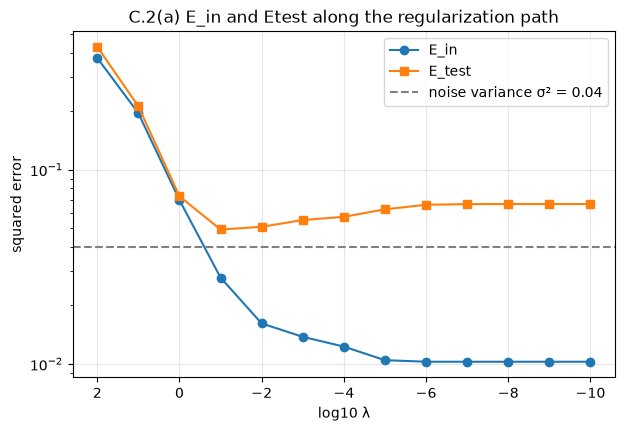

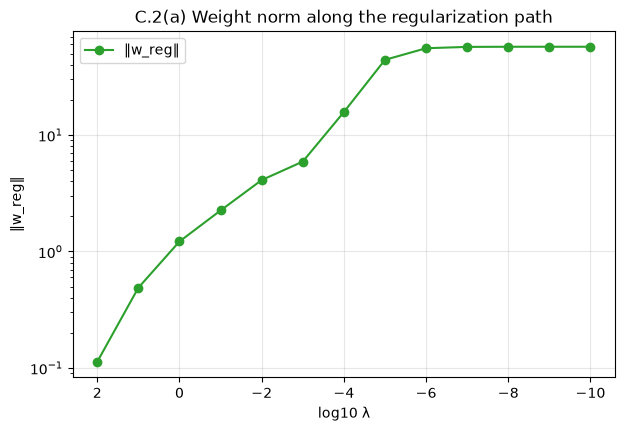

In [45]:
fig, ax = new_ax("log10 λ", "squared error", "C.2(a) E_in and Etest along the regularization path", logy=True)
ax.plot(path_df["log10 lambda"], path_df["E_in"], "o-", label="E_in")
ax.plot(path_df["log10 lambda"], path_df["E_test"], "s-", label="E_test")
ax.axhline(NOISE_STD**2, ls="--", c="gray", label="noise variance σ² = 0.04")
ax.invert_xaxis() # left = strong regularization, right = weak
ax.legend(); fig.savefig("C2a_errors.png", dpi=150)

fig, ax = new_ax("log10 λ", "‖w_reg‖", "C.2(a) Weight norm along the regularization path", logy=True)
ax.plot(path_df["log10 lambda"], path_df["||w_reg||"], "o-", c="C2", label="‖w_reg‖")
ax.invert_xaxis()
ax.legend(); fig.savefig("C2a_norm.png", dpi=150)

---

C.2(b) Best λ and the three regions

In [46]:
best = path_df.loc[path_df["E_test"].idxmin()]
print(f"Smallest E_test = {best['E_test']:.5f} at log10 lambda = {int(best['log10 lambda'])}")

Smallest E_test = 0.04919 at log10 lambda = -1


log10 λ = -1 gives the smallest E_test, and a bit lower E_in

log10 λ in [-2, 0] are over-regularized, the wights are pushed toward 0, and model becomes too simple, keeping bot E_in and E_test high, and close to each other, and ‖w‖ is small

log10 λ in [-2, -10] is under-regularized, E_in keeps falling but E_test rises, and ‖w‖ grows, meaning that polynomial is fitting the noise. 

---

C.2(c) Fitted curves for log10 λ ∈ {2, −3, −10}

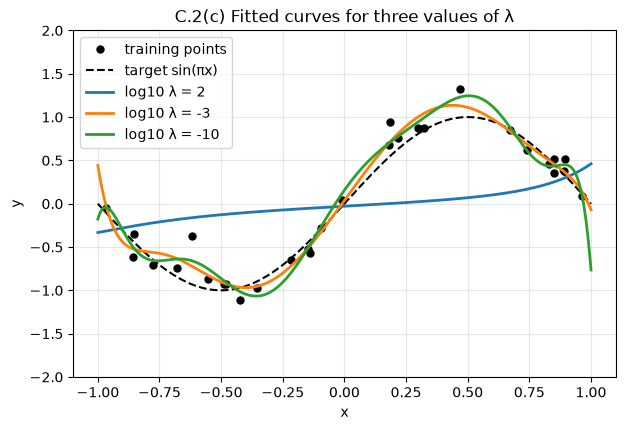

In [47]:
x_plot = np.linspace(-1, 1, 500)
Z_plot = features(x_plot, scaler)

fig, ax = new_ax("x", "y", "C.2(c) Fitted curves for three values of λ")
ax.plot(x_tr, y_tr, "ko", ms=5, label="training points")
ax.plot(x_plot, np.sin(np.pi * x_plot), "k--", lw=1.5, label="target sin(πx)")
for ll in [2, -3, -10]:
    w = ridge(Z_tr, y_tr, 10.0 ** ll)
    ax.plot(x_plot, Z_plot @ w, lw=2, label=f"log10 λ = {ll}")
ax.set_ylim(-2, 2)
ax.legend(); fig.savefig("C2c_fits.png", dpi=150)

log10 λ = 2 is underfitted and looks nearly flat, log10 λ = -10 is weaving around each point which corresponds to overfitting
